In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.formula.api import ols
import math

In [95]:
df = pd.DataFrame({
    'Temperature': [10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32],
    'Efficiency': [54, 62, 70, 76, 82, 85, 87, 86, 83, 78, 72, 64]
})
df.head()

,Temperature,Efficiency
0,10,54
1,12,62
2,14,70
3,16,76
4,18,82


yhat = -24.8644 -24.864386x + 9.9921x^2


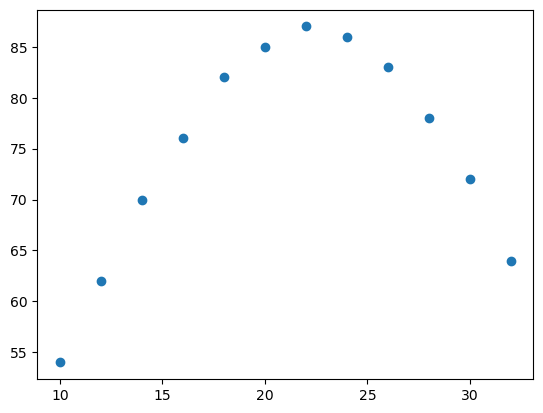

In [96]:
x = df[['Temperature']]
y = df['Efficiency']
X = sm.add_constant(x)

model = sm.OLS(y,X).fit()

plt.scatter(df['Temperature'], df['Efficiency']);

temp_2 = df['Temperature']**2
data2 = pd.DataFrame(temp_2)
data2 = data2.rename(columns = {'Temperature': 'Temp_sqr'})
df = pd.concat([df,data2], axis = 1)

x = df[['Temperature', 'Temp_sqr']]
y = df['Efficiency']
X = sm.add_constant(x)
model2 = sm.OLS(y,X).fit()

model2.params
b0 = model2.params['const']
b1 = model2.params['Temperature']
b2 = model2.params['Temp_sqr']

print(f'yhat = {b0:.4f} {b0:4f}x + {b1:.4f}x^2')

In [98]:
df = pd.DataFrame({
    'Experience': [1, 3, 5, 7, 2, 4, 6, 8, 10, 12, 1, 3, 5, 7, 9, 11],
    'Education': ['HBO', 'WO', 'HBO', 'WO', 'WO', 'HBO', 'WO', 'HBO',
                  'WO', 'HBO', 'HBO', 'WO', 'WO', 'HBO', 'WO', 'HBO'],
    'Gender': ['Male', 'Female', 'Female', 'Male', 'Male', 'Female',
               'Female', 'Male', 'Male', 'Female', 'Female', 'Male',
               'Male', 'Female', 'Female', 'Male'],
    'Salary': [2850, 3450, 3550, 4300, 3200, 3300, 4050, 4100,
               4900, 4750, 2900, 3500, 3900, 3950, 4700, 4650]
})

df.head()

df_ols = df.copy()
df_ols.columns = ['Experience', 'Education', 'Gender', 'Salary']
model = ols('Salary ~ Experience + C(Education) + C(Gender)', data = df_ols).fit()
model.summary()

c:\Users\feeva\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=16 observations were given.
  return hypotest_fun_in(*args, **kwds)


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.991
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                     428.0
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.84e-12
Time:                        14:53:24   Log-Likelihood:                -88.661
No. Observations:                  16   AIC:                             185.3
Df Residuals:                      12   BIC:                             188.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           2610.8500     43.151     60.505      0.000    2516.833    2704.867
C(Education)[T.WO]   334.4041     36.903      9.062      0.000     253.999     414.809
C(Gender)[T.Male]     10.1490     36.801      0.276      0.787     -70.034      90.332
Experience           186.3827      5.301     35.161      0.000     174.833     197.932
==============================================================================
Omnibus:                        0.384   Durbin-Watson:                   2.569
Prob(Omnibus):                  0.825   Jarque-Bera (JB):                0.418
Skew:                          -0.300   Prob(JB):                        0.811
Kurtosis:                       2.484   Cond. No.                         18.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [103]:
df1 = df.copy()
pd.get_dummies(df1, columns = ['Education', 'Gender'], dtype = 'Int64')

,Experience,Salary,Education_HBO,Education_WO,Gender_Female,Gender_Male
0,1,2850,1,0,0,1
1,3,3450,0,1,1,0
2,5,3550,1,0,1,0
3,7,4300,0,1,0,1
4,2,3200,0,1,0,1
5,4,3300,1,0,1,0
6,6,4050,0,1,1,0
7,8,4100,1,0,0,1
8,10,4900,0,1,0,1
9,12,4750,1,0,1,0
